# Minimax Linear Programming

What expected payoff can a player guarantee against every opposing action? Two linear programmes solve opposite sides of the same zero-sum matrix game.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Primal and dual strategies

The last unknown is the guaranteed value. Its bounds are unrestricted because a game can have a negative value.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gallery.games import ZERO_SUM, gap, show_mixes, trace_plot

from scipy.optimize import linprog


def maximin(A):
    m, n = A.shape
    payoff_constraints = np.column_stack([-A.T, np.ones(n)])
    normalise = np.r_[np.ones(m), 0][None, :]
    result = linprog(
        np.r_[np.zeros(m), -1],
        A_ub=payoff_constraints,
        b_ub=np.zeros(n),
        A_eq=normalise,
        b_eq=[1],
        bounds=[(0, None)] * m + [(None, None)],
        method="highs",
    )
    if not result.success:
        raise RuntimeError(result.message)
    return result.x[:-1], result.x[-1]

## Verify the equilibrium

Solving the transpose of the negated matrix gives the minimising player’s strategy and the other side of the value bound.

Row mix: [0.5714 0.4286 0.    ] Column mix: [0.4286 0.5714 0.    ]
Value 0.28571 | Primal–dual gap 0 | Best-response gap 1.11e-16


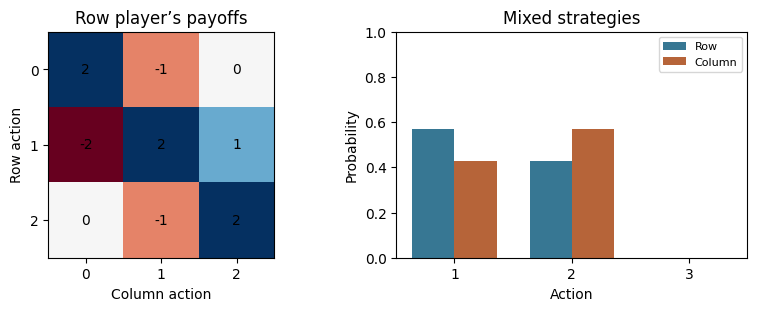

In [3]:
A = ZERO_SUM.copy()
p, lo = maximin(A)
q, negative_hi = maximin(-A.T)
print("Row mix:", np.round(p, 4), "Column mix:", np.round(q, 4))
print(
    f"Value {p@A@q:.5f} | Primal–dual gap {-negative_hi-lo:.3g} | Best-response gap {gap(A,p,q):.3g}"
)
assert np.isclose(p.sum(), 1) and np.isclose(q.sum(), 1) and gap(A, p, q) < 1e-7
fig, (a, b) = plt.subplots(1, 2, figsize=(7.7, 3), constrained_layout=True)
im = a.imshow(A, cmap="RdBu", vmin=-2, vmax=2)
a.set(
    title="Row player’s payoffs",
    xlabel="Column action",
    ylabel="Row action",
    xticks=range(3),
    yticks=range(3),
)
for (i, j), v in np.ndenumerate(A):
    a.text(j, i, str(int(v)), ha="center", va="center")
show_mixes(p, q, b)
plt.show()

## Reading the result

The best-response gap measures how far the pair is from a saddle point. It is zero up to numerical tolerance at an exact minimax solution.

## References

[Nash, Equilibrium Points in N-Person Games (1950)](https://doi.org/10.1073/pnas.36.1.48)

[SciPy, linear programming with HiGHS](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html)

[Payoff matrix and best-response diagnostics](../../gallery/games.py)